# **Cell 1 — Setup & Install**

In [1]:
!pip install -q sacrebleu rouge-score bert-score

from google.colab import drive
drive.mount('/content/drive')

from transformers import set_seed
set_seed(42)

import os
import pandas as pd
import numpy as np

PROJECT_ROOT = '/content/drive/MyDrive/Bengali Paraphrasing'
GEN_DIR = f'{PROJECT_ROOT}/outputs/generations'
METRICS_DIR = f'{PROJECT_ROOT}/outputs/metrics'
os.makedirs(METRICS_DIR, exist_ok=True)

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 3.3 MB/s eta 0:00:00
Mounted at /content/drive


# **Cell 2 — Load all four generation files**

In [2]:
ib_df = pd.read_parquet(f'{GEN_DIR}/indicbartss_generations.parquet')
bt5_df = pd.read_parquet(f'{GEN_DIR}/banglat5_generations.parquet')
tiger_df = pd.read_parquet(f'{GEN_DIR}/tigerllm_generations.parquet')
qwen_df = pd.read_parquet(f'{GEN_DIR}/qwen25_generations.parquet')

model_dfs = {
    'IndicBARTSS': ib_df,
    'BanglaT5': bt5_df,
    'TigerLLM': tiger_df,
    'Qwen2.5': qwen_df,
}

for name, df in model_dfs.items():
    print(f"{name}: {len(df)} rows")

IndicBARTSS: 23332 rows
BanglaT5: 23332 rows
TigerLLM: 23332 rows
Qwen2.5: 23332 rows


# **Cell 3 — Metric functions**

In [3]:
import sacrebleu
from rouge_score import rouge_scorer

# SacreBLEU -- tokenize='none' since we pass pre-tokenized (whitespace-split) Bengali text
def compute_sacrebleu(hypothesis, reference):
    hyp_tok = " ".join(hypothesis.split())
    ref_tok = " ".join(reference.split())
    return sacrebleu.sentence_bleu(hyp_tok, [ref_tok], tokenize='none').score

# ROUGE-L
class WhitespaceTokenizer:
    def tokenize(self, text):
        return text.split()

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False, tokenizer=WhitespaceTokenizer())
def compute_rouge_l(hypothesis, reference):
    return rouge.score(reference, hypothesis)['rougeL'].fmeasure

# PINC -- denominator = candidate n-gram count (verified correct)
def compute_pinc(candidate, source, max_n=4):
    def get_ngrams(text, n):
        tokens = text.split()
        return set(tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1)) if len(tokens) >= n else set()
    total_overlap_ratio, valid_n = 0, 0
    for n in range(1, max_n+1):
        cand_ngrams = get_ngrams(candidate, n)
        if len(cand_ngrams) == 0:
            continue
        overlap = len(cand_ngrams & get_ngrams(source, n))
        total_overlap_ratio += overlap / len(cand_ngrams)
        valid_n += 1
    return 1 - (total_overlap_ratio / valid_n) if valid_n else 0.0

print("Metric functions defined (SacreBLEU: tokenize='none'; ROUGE-L: no stemmer; PINC: candidate-normalized).")

Metric functions defined (SacreBLEU: tokenize='none'; ROUGE-L: no stemmer; PINC: candidate-normalized).


# **Cell 4 — Manual ROUGE Bengali tokenization sanity check**

In [4]:
test_ref = ib_df.iloc[0]['target']
test_hyp = ib_df.iloc[0]['generated']
print("Reference:", test_ref)
print("Generated:", test_hyp)
print("Reference split():", test_ref.split())
print("ROUGE-L score:", compute_rouge_l(test_hyp, test_ref))

Reference: কয়েকদিন আগে আমি প্যারিসে ছিলাম।
Generated: আমি প্যারিস থেকে প্যারিসে চলে এসেছি।
Reference split(): ['কয়েকদিন', 'আগে', 'আমি', 'প্যারিসে', 'ছিলাম।']
ROUGE-L score: 0.3636363636363636


# **Cell 5 — Whitespace/Artifact canonicalization across all four files**

In [5]:
def canonicalize(text):
    return " ".join(str(text).split())  # collapses multiple spaces, strips leading/trailing whitespace

for name, df in model_dfs.items():
    df['generated'] = df['generated'].apply(canonicalize)
    df['target'] = df['target'].apply(canonicalize)
    df['source'] = df['source'].apply(canonicalize)
print("Canonicalized whitespace across all four files.")

Canonicalized whitespace across all four files.


# **Cell 6 — Timing test (small sample, all 3 non-BERTScore metrics first)**

In [6]:
import time

sample_df = ib_df.sample(n=200, random_state=42)

start = time.time()
for _, row in sample_df.iterrows():
    _ = compute_sacrebleu(row['generated'], row['target'])
    _ = compute_rouge_l(row['generated'], row['target'])
    _ = compute_pinc(row['generated'], row['source'])
elapsed = time.time() - start
print(f"SacreBLEU+ROUGE-L+PINC: {elapsed:.2f}s for 200 examples ({elapsed/200*1000:.2f} ms/example)")

SacreBLEU+ROUGE-L+PINC: 0.06s for 200 examples (0.29 ms/example)


# **Cell 7 — BERTScore timing test with BanglaBERT**

In [7]:
!pip install -q git+https://github.com/csebuetnlp/normalizer

from bert_score import score as bertscore_score
from normalizer import normalize
from transformers import AutoTokenizer

BERTSCORE_MODEL = "csebuetnlp/banglabert"

# BanglaBERT's tokenizer_config.json doesn't set model_max_length, so transformers
# defaults to a huge sentinel value (~1e30) that overflows the Rust truncation backend.
# Patch AutoTokenizer.from_pretrained so any tokenizer it loads gets a sane max length.
_original_from_pretrained = AutoTokenizer.from_pretrained.__func__

def _patched_from_pretrained(cls, *args, **kwargs):
    tok = _original_from_pretrained(cls, *args, **kwargs)
    if tok.model_max_length > 100_000:
        tok.model_max_length = 512
    return tok

AutoTokenizer.from_pretrained = classmethod(_patched_from_pretrained)

sample_df = ib_df.sample(n=200, random_state=42)
sample_hyps = [normalize(t) for t in sample_df['generated'].tolist()]
sample_refs = [normalize(t) for t in sample_df['target'].tolist()]

start = time.time()
P, R, F1 = bertscore_score(
    sample_hyps, sample_refs,
    model_type=BERTSCORE_MODEL,
    num_layers=12,
    rescale_with_baseline=False,
    use_fast_tokenizer=False,
    verbose=True
)
elapsed = time.time() - start
print(f"\nBERTScore (BanglaBERT): {elapsed:.2f}s for 200 examples ({elapsed/200*1000:.2f} ms/example)")
print(f"Mean F1: {F1.mean().item():.4f}")

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.0/185.0 kB 8.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 5.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/528k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/7 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/4 [00:00<?, ?it/s]

done in 2.84 seconds, 70.31 sentences/sec

BERTScore (BanglaBERT): 10.13s for 200 examples (50.64 ms/example)
Mean F1: 0.9386


# **Cell 8 - Full metric computation, all four models**

In [8]:
# Cell 9 -- Full metric computation, all four models
import time

all_results = []

for model_name, df in model_dfs.items():
    checkpoint_path = f'{METRICS_DIR}/{model_name.lower()}_metrics.parquet'

    if os.path.exists(checkpoint_path):
        print(f"{model_name}: already scored, loading from disk.")
        model_metrics_df = pd.read_parquet(checkpoint_path)
        all_results.append(model_metrics_df)
        continue

    print(f"\n=== Scoring {model_name} ({len(df)} examples) ===")
    start = time.time()

    # --- BLEU, ROUGE-L, PINC (fast, per-sentence loop) ---
    bleu_scores, rouge_scores, pinc_scores = [], [], []
    for _, row in df.iterrows():
        bleu_scores.append(compute_sacrebleu(row['generated'], row['target']))
        rouge_scores.append(compute_rouge_l(row['generated'], row['target']))
        pinc_scores.append(compute_pinc(row['generated'], row['source']))

    # --- BERTScore (batched, GPU) ---
    hyps = [normalize(t) for t in df['generated'].tolist()]
    refs = [normalize(t) for t in df['target'].tolist()]
    P, R, F1 = bertscore_score(hyps, refs, model_type=BERTSCORE_MODEL, num_layers=12,
                                rescale_with_baseline=False, batch_size=64, verbose=True)

    model_metrics_df = pd.DataFrame({
        'model': model_name,
        'source': df['source'].values,
        'target': df['target'].values,
        'generated': df['generated'].values,
        'bleu': bleu_scores,
        'rouge_l': rouge_scores,
        'bertscore_f1': F1.numpy(),
        'pinc': pinc_scores,
    })

    model_metrics_df.to_parquet(checkpoint_path, index=False)
    elapsed = time.time() - start
    print(f"{model_name} done in {elapsed:.1f}s. Mean BLEU={model_metrics_df['bleu'].mean():.2f}, "
          f"ROUGE-L={model_metrics_df['rouge_l'].mean():.3f}, BERTScore={model_metrics_df['bertscore_f1'].mean():.3f}, "
          f"PINC={model_metrics_df['pinc'].mean():.3f}")

    all_results.append(model_metrics_df)

print("\nAll four models scored.")


=== Scoring IndicBARTSS (23332 examples) ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraModel LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED |  | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED |  | 
discriminator_predictions.dense.weight            | UNEXPECTED |  | 
discriminator_predictions.dense.bias              | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


calculating scores...
computing bert embedding.


  0%|          | 0/729 [00:00<?, ?it/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/729 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/365 [00:00<?, ?it/s]

done in 79.39 seconds, 293.89 sentences/sec
Qwen2.5 done in 93.2s. Mean BLEU=12.71, ROUGE-L=0.377, BERTScore=0.923, PINC=0.773

All four models scored.


# **Cell 9 - Combine into final long-format table**

In [9]:
# Cell 10 -- Combine into final long-format table
combined_df = pd.concat(all_results, ignore_index=True)
print(f"Combined table: {len(combined_df)} rows (expected {4 * 23332})")

combined_path_parquet = f'{METRICS_DIR}/all_metrics_long_format.parquet'
combined_path_csv = f'{METRICS_DIR}/all_metrics_long_format.csv'
combined_df.to_parquet(combined_path_parquet, index=False)
combined_df.to_csv(combined_path_csv, index=False, encoding='utf-8-sig')

print("Saved:", combined_path_parquet)
print("Saved:", combined_path_csv)

# Quick summary table
summary = combined_df.groupby('model')[['bleu', 'rouge_l', 'bertscore_f1', 'pinc']].mean()
print("\n=== Mean scores per model ===")
print(summary)

Combined table: 93328 rows (expected 93328)
Saved: /content/drive/MyDrive/Bengali Paraphrasing/outputs/metrics/all_metrics_long_format.parquet
Saved: /content/drive/MyDrive/Bengali Paraphrasing/outputs/metrics/all_metrics_long_format.csv

=== Mean scores per model ===
                  bleu   rouge_l  bertscore_f1      pinc
model                                                   
BanglaT5     18.884651  0.481991      0.947241  0.630313
IndicBARTSS  14.068395  0.417250      0.938589  0.564960
Qwen2.5      12.708026  0.377383      0.922841  0.773393
TigerLLM     18.693602  0.465506      0.941921  0.776726


# **Cell 10 — Build a model-level summary table (means + params)**

In [10]:
import json

with open(f'{PROJECT_ROOT}/outputs/generations/seq2seq_model_documentation.json') as f:
    seq2seq_doc = json.load(f)
with open(f'{PROJECT_ROOT}/outputs/generations/decoder_model_documentation.json') as f:
    decoder_doc = json.load(f)

summary = combined_df.groupby('model')[['bleu', 'rouge_l', 'bertscore_f1', 'pinc']].mean().reset_index()

param_map = {
    'IndicBARTSS': {'params': seq2seq_doc['IndicBARTSS']['total_params'], 'method': 'Full Fine-Tune'},
    'BanglaT5': {'params': seq2seq_doc['BanglaT5']['total_params'], 'method': 'Full Fine-Tune'},
    'TigerLLM': {'params': decoder_doc['TigerLLM']['trainable_lora_params'], 'method': 'QLoRA'},
    'Qwen2.5': {'params': decoder_doc['Qwen2.5']['trainable_lora_params'], 'method': 'QLoRA'},
}

summary['trainable_params'] = summary['model'].map(lambda m: param_map[m]['params'])
summary['method'] = summary['model'].map(lambda m: param_map[m]['method'])

print(summary)
summary.to_csv(f'{METRICS_DIR}/model_summary.csv', index=False)

         model       bleu   rouge_l  bertscore_f1      pinc  trainable_params  \
0     BanglaT5  18.884651  0.481991      0.947241  0.630313         247577856   
1  IndicBARTSS  14.068395  0.417250      0.938589  0.564960         244018176   
2      Qwen2.5  12.708026  0.377383      0.922841  0.773393          18464768   
3     TigerLLM  18.693602  0.465506      0.941921  0.776726          13045760   

           method  
0  Full Fine-Tune  
1  Full Fine-Tune  
2           QLoRA  
3           QLoRA  


# **Cell 11 — Adequacy-Diversity Scatter (BERTScore vs PINC)**

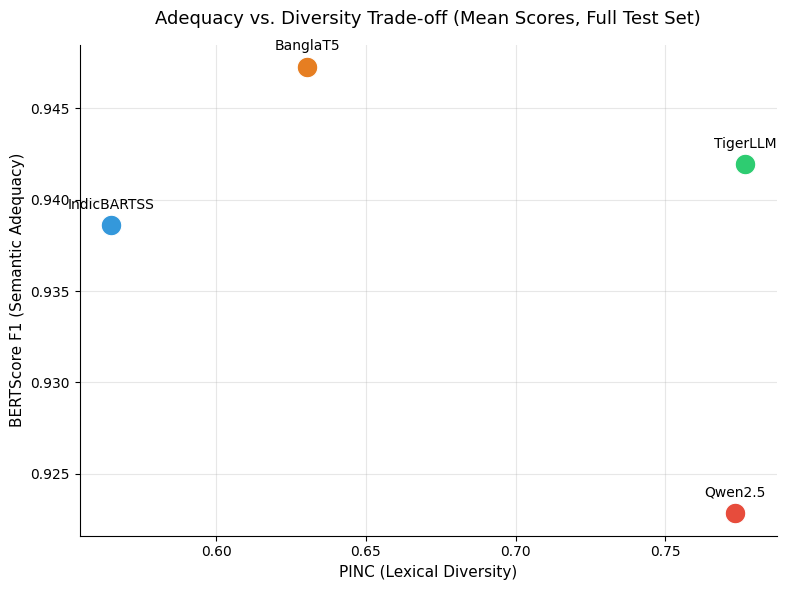

Saved adequacy-diversity scatter.


In [11]:
import matplotlib.pyplot as plt

colors = {'IndicBARTSS': '#3498db', 'BanglaT5': '#e67e22', 'TigerLLM': '#2ecc71', 'Qwen2.5': '#e74c3c'}

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

for _, row in summary.iterrows():
    ax.scatter(
        row['pinc'], row['bertscore_f1'],
        s=220,  # marker size (matplotlib uses points^2, roughly comparable to plotly's 22)
        color=colors[row['model']],
        edgecolors='white', linewidths=0.8,
        zorder=3
    )
    ax.annotate(
        row['model'],
        (row['pinc'], row['bertscore_f1']),
        textcoords="offset points", xytext=(0, 12),
        ha='center', fontsize=10, fontweight='medium'
    )

ax.set_title('Adequacy vs. Diversity Trade-off (Mean Scores, Full Test Set)', fontsize=13, pad=15)
ax.set_xlabel('PINC (Lexical Diversity)', fontsize=11)
ax.set_ylabel('BERTScore F1 (Semantic Adequacy)', fontsize=11)
ax.grid(True, alpha=0.3, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save both formats
fig.savefig(f'{METRICS_DIR}/adequacy_diversity_scatter.svg', format='svg', bbox_inches='tight')
fig.savefig(f'{METRICS_DIR}/adequacy_diversity_scatter.png', format='png', dpi=300, bbox_inches='tight')

plt.show()
print("Saved adequacy-diversity scatter.")

# **Cell 12 — Metric Suite Grouped Bar Chart**

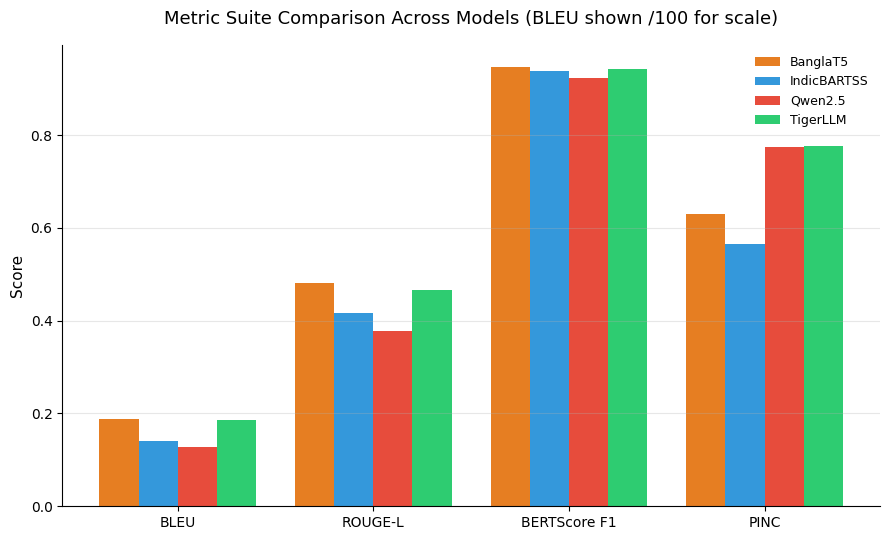

Saved metric suite bar chart.


In [12]:
import numpy as np
import matplotlib.pyplot as plt

metrics_to_plot = ['bleu', 'rouge_l', 'bertscore_f1', 'pinc']
metric_labels = ['BLEU', 'ROUGE-L', 'BERTScore F1', 'PINC']

models = summary['model'].tolist()
n_models = len(models)
n_metrics = len(metric_labels)

x = np.arange(n_metrics)  # positions for metric groups
bar_width = 0.8 / n_models  # total group width 0.8, split across models

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=100)

for i, model in enumerate(models):
    row = summary[summary['model'] == model].iloc[0]
    values = [row['bleu']/100, row['rouge_l'], row['bertscore_f1'], row['pinc']]  # BLEU/100 for comparable 0-1 scale
    offset = (i - (n_models - 1) / 2) * bar_width
    ax.bar(
        x + offset, values, width=bar_width,
        label=model, color=colors[model]
    )

ax.set_title('Metric Suite Comparison Across Models (BLEU shown /100 for scale)', fontsize=13, pad=15)
ax.set_ylabel('Score', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(metric_labels, fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.grid(True, axis='y', alpha=0.3, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save both formats
fig.savefig(f'{METRICS_DIR}/metric_suite_bar_chart.svg', format='svg', bbox_inches='tight')
fig.savefig(f'{METRICS_DIR}/metric_suite_bar_chart.png', format='png', dpi=300, bbox_inches='tight')

plt.show()
print("Saved metric suite bar chart.")

# **Cell 13 — Parameter-Efficiency Scatter (log-scale)**

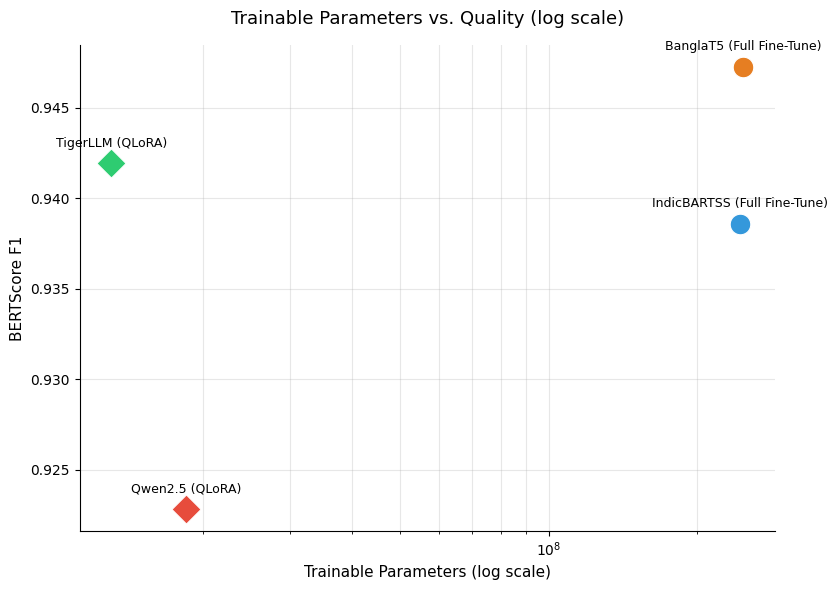

Saved parameter-efficiency scatter.


In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.5, 6), dpi=100)

for _, row in summary.iterrows():
    marker_symbol = 'o' if row['method'] == 'Full Fine-Tune' else 'D'  # circle vs diamond
    ax.scatter(
        row['trainable_params'], row['bertscore_f1'],
        s=220,
        color=colors[row['model']],
        marker=marker_symbol,
        edgecolors='white', linewidths=0.8,
        zorder=3
    )
    ax.annotate(
        f"{row['model']} ({row['method']})",
        (row['trainable_params'], row['bertscore_f1']),
        textcoords="offset points", xytext=(0, 12),
        ha='center', fontsize=9, fontweight='medium'
    )

ax.set_xscale('log')
ax.set_title('Trainable Parameters vs. Quality (log scale)', fontsize=13, pad=15)
ax.set_xlabel('Trainable Parameters (log scale)', fontsize=11)
ax.set_ylabel('BERTScore F1', fontsize=11)
ax.grid(True, which='both', alpha=0.3, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save both formats
fig.savefig(f'{METRICS_DIR}/param_efficiency_scatter.svg', format='svg', bbox_inches='tight')
fig.savefig(f'{METRICS_DIR}/param_efficiency_scatter.png', format='png', dpi=300, bbox_inches='tight')

plt.show()
print("Saved parameter-efficiency scatter.")

# **Cell 14 — Violin plots (per-sentence score distributions)**

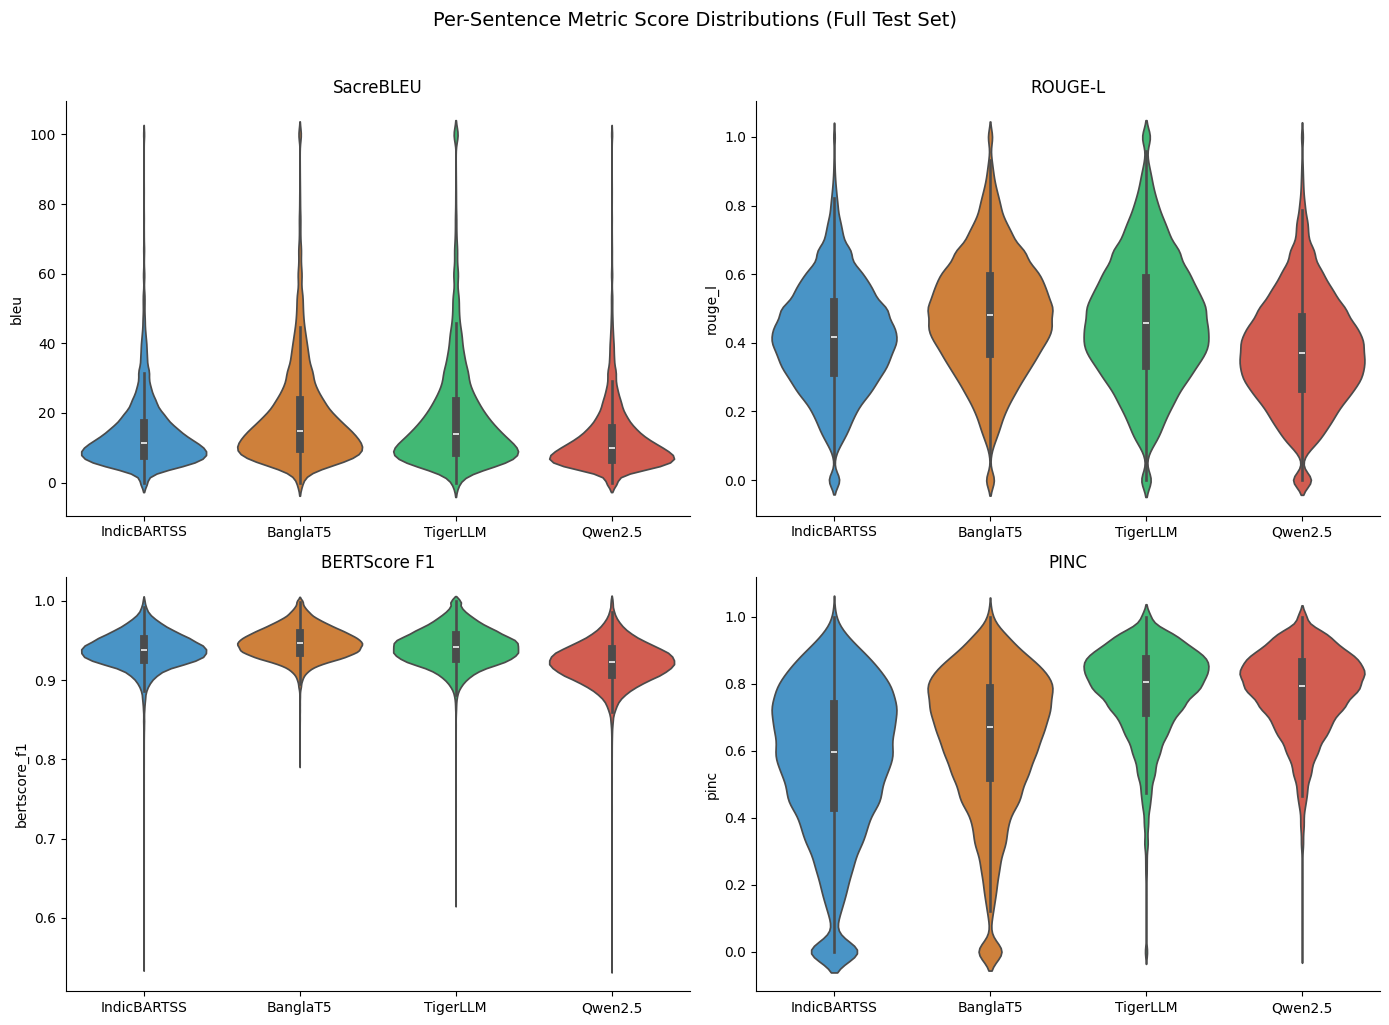

Saved distribution violin plots.


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=100)
metrics = ['bleu', 'rouge_l', 'bertscore_f1', 'pinc']
titles = ['SacreBLEU', 'ROUGE-L', 'BERTScore F1', 'PINC']
model_order = ['IndicBARTSS', 'BanglaT5', 'TigerLLM', 'Qwen2.5']

for ax, metric, title in zip(axes.flat, metrics, titles):
    sns.violinplot(
        data=combined_df, x='model', y=metric, order=model_order,
        hue='model', palette=colors, legend=False, ax=ax
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Per-Sentence Metric Score Distributions (Full Test Set)', y=1.02, fontsize=14)
plt.tight_layout()

# Save both formats
plt.savefig(f'{METRICS_DIR}/distribution_violin_plots.svg', format='svg', bbox_inches='tight')
plt.savefig(f'{METRICS_DIR}/distribution_violin_plots.png', format='png', dpi=300, bbox_inches='tight')

plt.show()
print("Saved distribution violin plots.")

# **check the real distribution before picking bins**

In [16]:
print(combined_df['source_word_count'].describe())
print(combined_df['source_word_count'].quantile([0.5, 0.75, 0.9, 0.95, 0.99]))

count    93328.000000
mean        11.522844
std          5.416701
min          3.000000
25%          8.000000
50%         10.000000
75%         14.000000
max         57.000000
Name: source_word_count, dtype: float64
0.50    10.0
0.75    14.0
0.90    19.0
0.95    22.0
0.99    29.0
Name: source_word_count, dtype: float64


# **Cell 15 — Length-stratified performance**

/tmp/ipykernel_1698/1673299393.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  length_perf = combined_df.groupby(['model', 'length_bucket'])['bertscore_f1'].mean().reset_index()
/tmp/ipykernel_1698/1673299393.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bucket_counts = combined_df.groupby('length_bucket').size()


length_bucket
1-6      13492
7-9      25824
10-12    21904
13-16    17572
17-22    10564
23+       3972
dtype: int64


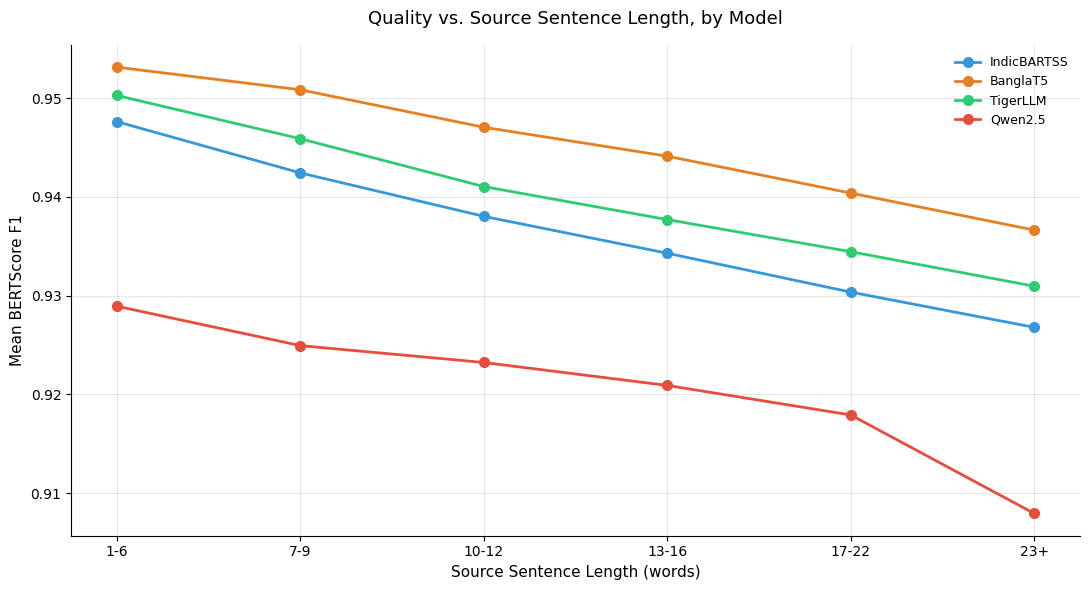

Saved length-stratified performance chart.


In [17]:
combined_df['source_word_count'] = combined_df['source'].str.split().str.len()

bins = [0, 6, 9, 12, 16, 22, 60]
labels = ['1-6', '7-9', '10-12', '13-16', '17-22', '23+']
combined_df['length_bucket'] = pd.cut(combined_df['source_word_count'], bins=bins, labels=labels)

length_perf = combined_df.groupby(['model', 'length_bucket'])['bertscore_f1'].mean().reset_index()
bucket_counts = combined_df.groupby('length_bucket').size()
print(bucket_counts)

fig, ax = plt.subplots(figsize=(11, 6), dpi=100)
for model in model_order:
    subset = length_perf[length_perf['model'] == model]
    ax.plot(
        subset['length_bucket'], subset['bertscore_f1'],
        marker='o', color=colors[model], label=model,
        linewidth=2, markersize=7
    )

ax.set_xlabel('Source Sentence Length (words)', fontsize=11)
ax.set_ylabel('Mean BERTScore F1', fontsize=11)
ax.set_title('Quality vs. Source Sentence Length, by Model', fontsize=13, pad=15)
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save both formats
plt.savefig(f'{METRICS_DIR}/length_stratified_performance.svg', format='svg', bbox_inches='tight')
plt.savefig(f'{METRICS_DIR}/length_stratified_performance.png', format='png', dpi=300, bbox_inches='tight')

plt.show()
print("Saved length-stratified performance chart.")

# **CELL 16 - Qualitative comparison table — sampled from the test set (same data as reported metrics)**

In [18]:
# Qualitative comparison table — sampled from the test set (same data as reported metrics)
qual_sample = ib_df.sample(n=5, random_state=42)

qual_table = pd.DataFrame({
    'Source': qual_sample['source'].values,
    'Reference': qual_sample['target'].values,
    'IndicBARTSS': qual_sample['generated'].values,
    'BanglaT5': bt5_df.loc[qual_sample.index, 'generated'].values,
    'TigerLLM': tiger_df.loc[qual_sample.index, 'generated'].values,
    'Qwen2.5': qwen_df.loc[qual_sample.index, 'generated'].values,
})

qual_table.to_csv(f'{METRICS_DIR}/qualitative_comparison_table.csv', index=False, encoding='utf-8-sig')
qual_table

,Source,Reference,IndicBARTSS,BanglaT5,TigerLLM,Qwen2.5
0,"দীর্ঘ ভ্রমণে ক্লান্ত সবাই, সকালেই রওনা দিতে হব...","দীর্ঘ যাত্রায় ক্লান্ত, সকালে আমাদের চলে যেতে ...","দীর্ঘ ভ্রমণ শেষে, সবাই সকালে আবার ফিরে আসবে।","দীর্ঘ ভ্রমণের কারণে ক্লান্ত সবাই, সকালে রওনা দ...",দীর্ঘ ভ্রমণে ক্লান্ত হয়ে পড়া লোকদের সকালেই ফ...,"সবাই দীর্ঘ ভ্রমণে ক্লান্ত হয়েছে, সকালে আবার র..."
1,এ বাড়িতে সাধারণত কোনো ঝগড়াঝাঁটি হয় না।,এ বাড়িতে কোনো ঝগড়া নেই।,এ বাড়িতে সাধারণত কোনো ঝগড়া হয় না।,এ বাড়িতে সাধারণত কোনো ঝগড়া হয় না।,বাড়িতে সাধারণত কোনো ঝগড়া হয় না।,এই ঘরে সাধারণত কোন ঝগড়া হয় না।
2,কিছু ভিডিওতে কল্পিত শত্রুর বিরুদ্ধে বদলা নেওয়...,কিছু ভিডিও কাল্পনিক শত্রুদের বিরুদ্ধে প্রতিশোধ...,কিছু ভিডিওতে শত্রুর বিরুদ্ধে শত্রুর বিরুদ্ধে য...,কিছু ভিডিওতে কাল্পনিক শত্রুর বিরুদ্ধে প্রতিশোধ...,"কিছু ভিডিওতে, কল্পিত শত্রুদের প্রতি প্রতিশোধ ন...",কিছু ভিডিওতে কল্পনাগত শত্রুর বিরুদ্ধে পরিবর্তন...
3,প্রথম দিনে মোট ২৬ জনকে টিকা দেয়া হয়।,প্রথম দিন সর্বমোট ২৬ জনকে অনাক্রম্য করা হয়।,প্রথম দিনে ২৬ জন টিকা প্রদান করা হয়।,প্রথম দিনে ২৬ জনকে টিকা দেওয়া হয়।,"প্রথম দিনে, ২৬ জন লোককে টিকা দেওয়া হয়।",প্রথম দিনে ২৬ জনকে টিকা প্রদান করা হয়।
4,দেসিয়াস তখন শত্রুদলের মধ্যে ঝাঁপ দেন।,এরপর দেসিয়াস শত্রুদের মধ্যে ঝাঁপিয়ে পড়েছিলেন।,দেসিয়াস শত্রুদের বিরুদ্ধে যুদ্ধে ঝাঁপিয়ে পড়ে।,দেসিয়াস তখন শত্রু দলের মধ্যে ঝাঁপ দেন।,এরপর ডেসিয়াস শত্রুদের মধ্যে ঝাঁপিয়ে পড়ে।,দেসিয়াস সেই সময়ে শত্রুদলের মধ্যে পড়াশোনা কর...


# **Training time vs quality scatter**